# Пакетная аналитика над хранилищем (HDFS + Spark)

Работает поверх слоёв, которые строит DAG `bank_elt` в Airflow:

| слой | путь в HDFS | формат |
|---|---|---|
| raw | `/datalake/raw/<source>/<table>/batch=YYYY-MM/*.csv.gz` | CSV, gzip — как пришло из источника |
| core | `/datalake/core/fact_transactions/txn_month=…`, `dim_*` | Parquet + zstd, звёздная схема |
| marts | `/datalake/marts/dm_*/txn_month=…` | Parquet + zstd, предагрегаты |
| meta | `/datalake/_meta/…` | манифесты загрузки, DQ-метрики, бенчмарк |

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from pipeline import settings
from pipeline.spark_jobs.common import spark_session, core_path, mart_path, hdfs_du, read_json_hdfs

# ноутбук берёт 2 ядра кластера, остальное остаётся DAG'ам Airflow
spark = spark_session("analytics-notebook", conf={"spark.cores.max": "2", "spark.executor.memory": "1536m",
                                                 "spark.sql.shuffle.partitions": "8"})
spark.sparkContext.setLogLevel("WARN")

for name in ["fact_transactions", "dim_terminal", "dim_client", "dim_account"]:
    spark.read.parquet(core_path(name)).createOrReplaceTempView(name)
for name in ["dm_daily_sales", "dm_retailer_monthly", "dm_client_monthly", "dm_hourly_load"]:
    spark.read.parquet(mart_path(name)).createOrReplaceTempView(name)

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
RETAILER_COLOR = {"X5 Group": C[0], "Магнит": C[1], "Прочие": C[2]}
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#8a8984", "lines.linewidth": 2, "font.size": 10})
sql = lambda q: spark.sql(q).toPandas()
spark.version

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/08 16:27:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.4'

## 1. Объёмы данных по слоям
Источник — манифесты загрузки (`load_manifest.json`) и `getContentSummary` HDFS.

In [ ]:
batches = sorted(r.batch for r in spark.read.json(settings.hdfs_url(f"{settings.META_ROOT}/batch=*/load_manifest.json"),
                                                     multiLine=True).select("batch").collect())
manifests = [read_json_hdfs(spark, f"{settings.META_ROOT}/batch={b}/load_manifest.json") for b in batches]
files = pd.DataFrame([f | {"batch": m["batch"]} for m in manifests for f in m["files"]])
mib = lambda b: round(b / 2**20, 1)
sizes = pd.DataFrame({
    "слой": ["landing CSV (все таблицы)", "landing CSV (транзакции)", "raw csv.gz (все)", "raw csv.gz (транзакции)",
             "core: fact_transactions", "core: измерения", "marts"],
    "MiB": [mib(files.raw_bytes.sum()), mib(files[files.table == "transactions"].raw_bytes.sum()),
            mib(hdfs_du(spark, settings.RAW_ROOT)), mib(files[files.table == "transactions"].gz_bytes.sum()),
            mib(hdfs_du(spark, settings.CORE_ROOT + "/fact_transactions")),
            mib(sum(hdfs_du(spark, f"{settings.CORE_ROOT}/{d}") for d in ["dim_terminal", "dim_client", "dim_account"])),
            mib(hdfs_du(spark, settings.MART_ROOT))]})
print(f"batch'ей: {len(batches)}, строк транзакций в источнике: {files[files.table=='transactions'].rows.sum():,}")
sizes

batch'ей: 12, строк транзакций в источнике: 21,604,320


,слой,MiB
0,landing CSV (все таблицы),2146.7
1,landing CSV (транзакции),1129.6
2,raw csv.gz (все),586.0
3,raw csv.gz (транзакции),326.4
4,core: fact_transactions,361.6
5,core: измерения,11.8
6,marts,82.3


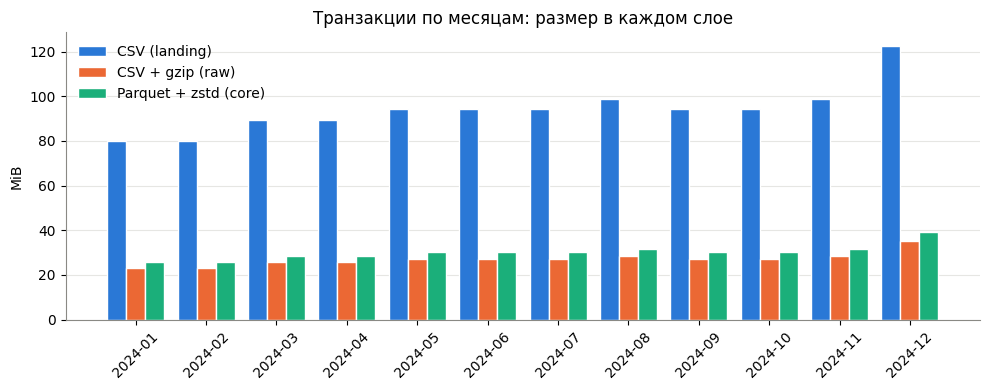

In [ ]:
tx = files[files.table == "transactions"].groupby("batch")[["raw_bytes", "gz_bytes"]].sum() / 2**20
fact_mb = pd.Series({b: hdfs_du(spark, f"{settings.CORE_ROOT}/fact_transactions/txn_month={b}") / 2**20 for b in tx.index})
fig, ax = plt.subplots()
w = 0.27
x = range(len(tx))
ax.bar([i - w for i in x], tx.raw_bytes, w, label="CSV (landing)", color=C[0], edgecolor="white", linewidth=1)
ax.bar(list(x), tx.gz_bytes, w, label="CSV + gzip (raw)", color=C[1], edgecolor="white", linewidth=1)
ax.bar([i + w for i in x], fact_mb, w, label="Parquet + zstd (core)", color=C[2], edgecolor="white", linewidth=1)
ax.set_xticks(list(x), tx.index, rotation=45); ax.set_ylabel("MiB")
ax.set_title("Транзакции по месяцам: размер в каждом слое"); ax.legend(frameon=False)
plt.tight_layout()

## 2. Качество данных по batch'ам
Метрики пишет Spark-джоб `raw_to_core`, проверяет задача `dq_core` в Airflow.

In [ ]:
rows = []
for b in batches:
    m = read_json_hdfs(spark, f"{settings.META_ROOT}/batch={b}/core_metrics.json")
    rows.append({"batch": b, "raw_rows": sum(m["raw_rows"].values()), "duplicates": sum(m["duplicates"].values()),
                 **{f"rej_{k}": v for k, v in m["rejected"].items()}, "fact_rows": m["fact_rows"],
                 "core_job_s": m["seconds"]})
dq = pd.DataFrame(rows).fillna(0)
dq

,batch,raw_rows,duplicates,rej_bad_amount,rej_unknown_terminal,rej_bad_timestamp,fact_rows,core_job_s
0,2024-01,1530306,306,153,153,153,1529541,34.1
1,2024-02,1530306,306,153,153,153,1529541,32.9
2,2024-03,1710342,342,171,171,171,1709487,35.8
3,2024-04,1710342,342,171,171,171,1709487,34.5
4,2024-05,1800360,360,180,180,180,1799460,38.1
5,2024-06,1800360,360,180,180,180,1799460,46.0
6,2024-07,1800360,360,180,180,180,1799460,36.1
7,2024-08,1890378,378,189,189,189,1889433,44.2
8,2024-09,1800360,360,180,180,180,1799460,38.0
9,2024-10,1800360,360,180,180,180,1799460,34.8


In [ ]:
spark.read.parquet(settings.hdfs_url(settings.QUARANTINE_ROOT + "/transactions/batch=*")) \
    .groupBy("source_bank", "reject_reason").count().orderBy("source_bank", "reject_reason").show()
spark.read.parquet(settings.hdfs_url(settings.QUARANTINE_ROOT + "/transactions/batch=*")).show(5, truncate=False)

+-----------+----------------+-----+
|source_bank|   reject_reason|count|
+-----------+----------------+-----+
|      bank1|      bad_amount| 1200|
|      bank1|   bad_timestamp| 1200|
|      bank1|unknown_terminal| 1200|
|      bank2|      bad_amount|  960|
|      bank2|   bad_timestamp|  960|
|      bank2|unknown_terminal|  960|
+-----------+----------------+-----+



+-----------+--------+-----------+----------+--------------------+----------+-------+----------------+
|source_bank|txn_id  |terminal_id|account_id|raw_transaction_date|raw_amount|status |reject_reason   |
+-----------+--------+-----------+----------+--------------------+----------+-------+----------------+
|bank1      |58759049|38286      |411164    |2024-12-02 14:58:36 |1337.43   |success|unknown_terminal|
|bank1      |58926631|2959       |418830    |0000-00-00 99:99:99 |783.15    |success|bad_timestamp   |
|bank1      |58955182|35948      |262737    |2024-12-07 11:20:33 |195.06    |success|unknown_terminal|
|bank1      |58970773|434        |133460    |0000-00-00 99:99:99 |376.43    |failed |bad_timestamp   |
|bank1      |59025906|30384      |437979    |2024-12-08 18:54:38 |NULL      |success|bad_amount      |
+-----------+--------+-----------+----------+--------------------+----------+-------+----------------+
only showing top 5 rows



## 3. Как Spark использует оптимизированную раскладку
Фильтр по месяцу и дню: в плане видно `PartitionFilters` (читается одна папка `txn_month`) и `PushedFilters`
(Parquet пропускает row group'ы по min/max статистике — внутри файла данные отсортированы по времени).
Читаются только нужные колонки (`ReadSchema`).

In [ ]:
q = spark.table("fact_transactions").filter("txn_month = '2024-06' and txn_date = '2024-06-15'") \
        .groupBy("txn_hour").agg(F.sum("amount"))
q.explain(mode="formatted")

== Physical Plan ==
AdaptiveSparkPlan (7)
+- HashAggregate (6)
   +- Exchange (5)
      +- HashAggregate (4)
         +- Project (3)
            +- Filter (2)
               +- Scan parquet  (1)


(1) Scan parquet 
Output [4]: [txn_date#3, txn_hour#4, amount#8, txn_month#12]
Batched: true
Location: InMemoryFileIndex [hdfs://namenode:9000/datalake/core/fact_transactions]
PartitionFilters: [isnotnull(txn_month#12), (txn_month#12 = 2024-06)]
PushedFilters: [IsNotNull(txn_date), EqualTo(txn_date,2024-06-15)]
ReadSchema: struct<txn_date:date,txn_hour:tinyint,amount:decimal(14,2)>

(2) Filter
Input [4]: [txn_date#3, txn_hour#4, amount#8, txn_month#12]
Condition : (isnotnull(txn_date#3) AND (txn_date#3 = 2024-06-15))

(3) Project
Output [2]: [txn_hour#4, amount#8]
Input [4]: [txn_date#3, txn_hour#4, amount#8, txn_month#12]

(4) HashAggregate
Input [2]: [txn_hour#4, amount#8]
Keys [1]: [txn_hour#4]
Functions [1]: [partial_sum(amount#8)]
Aggregate Attributes [2]: [sum#320, isEmpty#321]
Results 

## 4. Аналитика
### 4.1 Месячный оборот по ритейлерам (витрина `dm_daily_sales`)

turnover_mln                avg_check                
retailer      X5 Group Магнит  Прочие  X5 Group  Магнит  Прочие
txn_month                                                      
2024-01          472.2  441.0  1009.6    1018.7  1005.9  1995.2
2024-02          472.3  441.8  1008.8    1018.1  1008.2  1992.4
2024-03          527.3  491.9  1127.8    1017.0  1004.0  1992.1
2024-04          526.3  493.7  1128.0    1017.5  1006.9  1991.4
2024-05          555.0  518.1  1189.2    1017.7  1004.9  1995.3
2024-06          554.6  517.7  1187.7    1015.9  1003.7  1994.9
2024-07          554.3  519.2  1185.6    1016.4  1005.8  1991.7
2024-08          582.5  544.0  1245.6    1015.6  1004.9  1994.6
2024-09          555.7  517.6  1191.0    1017.8  1005.7  1999.7
2024-10          555.8  516.3  1187.0    1017.3  1002.6  1995.2
2024-11          583.5  543.2  1247.1    1017.2  1004.1  1994.3
2024-12          798.9  744.4  1705.6    1125.7  1110.4  2204.6

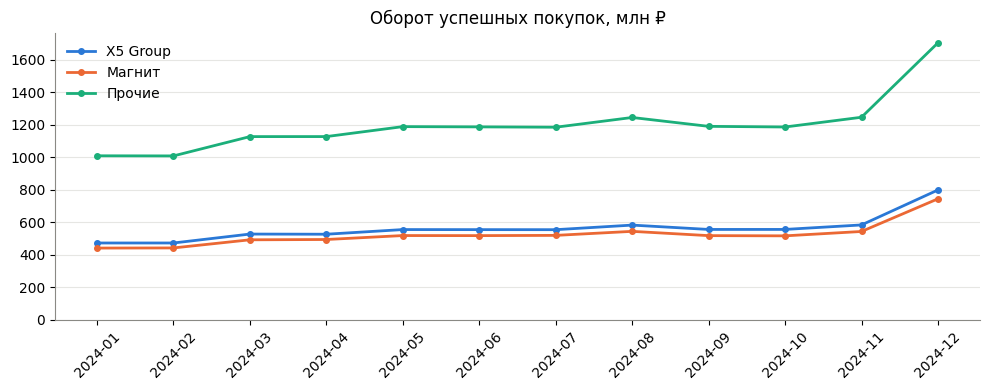

In [ ]:
m = sql("""
    select txn_month, retailer, cast(sum(turnover)/1e6 as double) as turnover_mln, sum(purchases_cnt) as purchases,
           cast(sum(turnover)/sum(purchases_cnt) as double) as avg_check
    from dm_daily_sales group by txn_month, retailer order by txn_month""")
p = m.pivot(index="txn_month", columns="retailer", values="turnover_mln")
fig, ax = plt.subplots()
for r in p.columns:
    ax.plot(p.index, p[r], marker="o", markersize=4, color=RETAILER_COLOR[r], label=r)
ax.set_title("Оборот успешных покупок, млн ₽"); ax.set_ylim(0); ax.legend(frameon=False, loc="upper left")
plt.xticks(rotation=45); plt.tight_layout()
m.pivot(index="txn_month", columns="retailer", values=["turnover_mln", "avg_check"]).round(1)

### 4.2 Топ-10 регионов по обороту магазинов X5 и Магнит за год

In [ ]:
sql("""
    select region,
           round(sum(case when retailer='X5 Group' then turnover end)/1e6, 1) as x5_mln,
           round(sum(case when retailer='Магнит' then turnover end)/1e6, 1)   as magnit_mln,
           round(sum(turnover)/1e6, 1) as total_mln,
           round(sum(turnover)/sum(purchases_cnt), 0) as avg_check
    from dm_daily_sales where retailer <> 'Прочие'
    group by region order by total_mln desc limit 10""")

,region,x5_mln,magnit_mln,total_mln,avg_check
0,Москва,1247.1,1086.1,2333.2,1021
1,Санкт-Петербург,590.8,522.3,1113.0,1026
2,Краснодарский край,451.3,414.9,866.2,1015
3,Московская область,396.1,416.8,813.0,1025
4,Свердловская область,340.8,318.6,659.4,1066
5,Новосибирская область,238.2,280.0,518.2,1016
6,Ростовская область,242.6,258.6,501.3,1018
7,Республика Татарстан,257.9,235.4,493.3,1014
8,Самарская область,227.8,218.4,446.2,1028
9,Башкортостан,252.3,188.2,440.5,1044


### 4.3 Форматы магазинов: средний чек, оборот на терминал, доля касс самообслуживания

In [ ]:
fmt = sql("""
    select retailer, store_format,
           round(sum(turnover)/sum(purchases_cnt), 0) as avg_check,
           round(sum(turnover)/1e6, 1) as turnover_mln,
           round(sum(case when checkout_type='самообслуживание' then purchases_cnt end) / sum(purchases_cnt), 3) as self_service_share,
           round(sum(turnover) / sum(active_terminals) / 1e3, 0) as turnover_per_terminal_month_k
    from dm_retailer_monthly where retailer <> 'Прочие'
    group by retailer, store_format order by retailer, avg_check desc""")
fmt

,retailer,store_format,avg_check,turnover_mln,self_service_share,turnover_per_terminal_month_k
0,X5 Group,Пятёрочка Макси,1416,946.4,0.227,38.0
1,X5 Group,Перекресток,1410,2729.3,0.234,37.0
2,X5 Group,Пятерочка,777,2636.9,0.226,21.0
3,X5 Group,Перекресток-экспресс,776,425.8,0.228,20.0
4,Магнит,Магнит Экстра,1441,922.8,0.173,37.0
5,Магнит,Магнит Семейный,1293,2715.5,0.194,36.0
6,Магнит,Магнит Косметик,964,891.5,0.180,27.0
7,Магнит,Магнит Аптека,870,508.9,0.183,25.0
8,Магнит,Магнит Сити,646,973.7,0.181,18.0
9,Магнит,Магнит Go,644,276.3,0.186,17.0


### 4.4 Нагрузка на кассы по дням недели и часам (витрина `dm_hourly_load`)

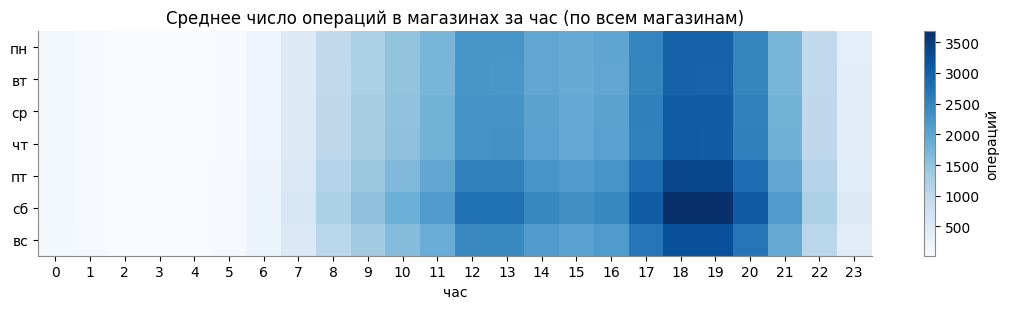

In [ ]:
h = sql("""
    select day_of_week, txn_hour, sum(attempts_cnt) / max(days_cnt) / 12 as avg_tx_per_day
    from dm_hourly_load where retailer <> 'Прочие'
    group by day_of_week, txn_hour""").pivot(index="day_of_week", columns="txn_hour", values="avg_tx_per_day")
fig, ax = plt.subplots(figsize=(11, 3.2))
im = ax.imshow(h.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(7), ["пн", "вт", "ср", "чт", "пт", "сб", "вс"]); ax.set_xticks(range(24), range(24))
ax.set_xlabel("час"); ax.set_title("Среднее число операций в магазинах за час (по всем магазинам)"); ax.grid(False)
fig.colorbar(im, ax=ax, label="операций"); plt.tight_layout()

### 4.5 Клиенты: возраст × пол (витрина `dm_client_monthly`)

In [ ]:
sql("""
    select age_group, gender,
           count(distinct client_key) as clients,
           round(avg(purchases_cnt), 1) as purchases_per_month,
           round(sum(turnover)/sum(purchases_cnt), 0) as avg_check,
           round(avg(active_days), 1) as active_days_per_month
    from dm_client_monthly group by age_group, gender order by age_group, gender""")

,age_group,gender,clients,purchases_per_month,avg_check,active_days_per_month
0,18-24,F,38262,3.7,1380,3.4
1,18-24,M,33840,3.7,1379,3.4
2,25-34,F,60635,3.7,1381,3.4
3,25-34,M,54266,3.7,1381,3.4
4,35-44,F,60460,3.7,1377,3.4
5,35-44,M,53911,3.8,1380,3.4
6,45-54,F,60396,3.7,1382,3.4
7,45-54,M,53988,3.7,1384,3.4
8,55+,F,112511,3.8,1382,3.4
9,55+,M,99511,3.7,1376,3.4


### 4.6 Удержание: доля клиентов месяца M, совершивших покупку в месяце M+1

In [ ]:
ret = sql("""
    with a as (select distinct txn_month, client_key from dm_client_monthly)
    select a.txn_month, count(*) as active_clients,
           round(count(b.client_key) / count(*), 3) as retained_next_month
    from a left join a b
      on b.client_key = a.client_key
     and b.txn_month = date_format(add_months(to_date(a.txn_month || '-01'), 1), 'yyyy-MM')
    where a.txn_month < (select max(txn_month) from a)
    group by a.txn_month order by a.txn_month""")
ret

,txn_month,active_clients,retained_next_month
0,2024-01,421983,0.808
1,2024-02,422201,0.831
2,2024-03,437038,0.825
3,2024-04,437004,0.835
4,2024-05,443812,0.833
5,2024-06,443958,0.832
6,2024-07,443718,0.842
7,2024-08,449959,0.830
8,2024-09,443632,0.832
9,2024-10,443437,0.842


### 4.7 Сравнение банков-эквайеров: отказы и возвраты

In [ ]:
sql("""
    select source_bank, retailer,
           sum(attempts_cnt) as attempts,
           round(sum(failed_cnt)/sum(attempts_cnt), 4) as failed_share,
           round(sum(refunds_amount)/sum(turnover), 4) as refund_to_turnover
    from dm_daily_sales group by source_bank, retailer order by source_bank, retailer""")

,source_bank,retailer,attempts,failed_share,refund_to_turnover
0,bank1,X5 Group,3872147,0.0494,0.0107
1,bank1,Магнит,3629563,0.0494,0.0108
2,bank1,Прочие,4494690,0.0495,0.0109
3,bank2,X5 Group,3241368,0.0497,0.0108
4,bank2,Магнит,3089618,0.0495,0.0109
5,bank2,Прочие,3266134,0.0495,0.0109


### 4.8 Детализация из core: самые загруженные терминалы декабря (звезда: факт + измерение)

In [ ]:
sql("""
    select t.retailer, t.store_format, t.region, t.city, t.address, t.checkout_type,
           count(*) as purchases, round(sum(f.amount)/1e3, 1) as turnover_k
    from fact_transactions f join dim_terminal t on f.terminal_key = t.terminal_key
    where f.txn_month = '2024-12' and f.status = 'success' and not f.is_refund and t.store_id is not null
    group by 1,2,3,4,5,6 order by purchases desc limit 10""")

,retailer,store_format,region,city,address,checkout_type,purchases,turnover_k
0,Магнит,Магнит Семейный,Красноярский край,Красноярск,ул. Школьная 105,касса,1099,1659.0
1,X5 Group,Перекресток,Башкортостан,Уфа,ул. Заводская 75,касса,1056,1789.5
2,X5 Group,Перекресток,Оренбургская область,Оренбург,ул. Советская 111,касса,994,1647.8
3,Магнит,Магнит Семейный,Краснодарский край,Краснодар,ул. Советская 139,касса,783,1226.0
4,Магнит,Магнит Сити,Москва,Москва,ул. Садовая 86,касса,783,572.9
5,Магнит,Магнит Семейный,Самарская область,Самара,ул. Молодёжная 133,касса,774,1161.5
6,Магнит,Магнит Семейный,Самарская область,Самара,ул. Гагарина 40,касса,755,1178.5
7,Магнит,Магнит Семейный,Кемеровская область,Кемерово,ул. Октябрьская 184,касса,751,1148.6
8,Магнит,Магнит Семейный,Нижегородская область,Нижний Новгород,ул. Московская 114,касса,739,1125.1
9,Магнит,Магнит Аптека,Краснодарский край,Краснодар,ул. Гагарина 155,касса,738,746.9


## 5. Тестирование скорости доступа к данным
Результат DAG `bank_elt_benchmark` (`/datalake/_meta/benchmark.json`). Одни и те же запросы
выполняются над raw (CSV.gz: каждый раз парсинг, типизация и сборка справочника), над core (Parquet)
и над витринами.

In [ ]:
bench = read_json_hdfs(spark, f"{settings.META_ROOT}/benchmark.json")
if bench is None:
    print("Запустите DAG bank_elt_benchmark")
else:
    qs = pd.DataFrame(bench["queries_seconds"]).T
    display(qs)
    codecs = pd.DataFrame({k: v for k, v in bench["codecs_one_month"].items() if k != "month"}).T
    codecs["MiB"] = (codecs["bytes"] / 2**20).round(1)
    display(codecs[["MiB", "write_s", "sum_amount_s", "one_day_count_s"]])

,raw_csv_gz,core_parquet,mart
Q1_turnover_by_month_retailer_region,88.10,2.72,0.18
Q2_hourly_x5_moscow_one_day,12.14,0.36,NaN
Q3_top10_clients_year,46.23,3.42,1.19


,MiB,write_s,sum_amount_s,one_day_count_s
csv/none,250.5,3.67,1.03,0.84
csv/gzip,52.6,6.23,1.48,1.40
parquet/none,104.3,2.72,0.15,0.16
parquet/snappy,59.0,2.69,0.14,0.12
parquet/gzip,39.4,5.00,0.17,0.12
parquet/zstd,37.7,2.78,0.14,0.10


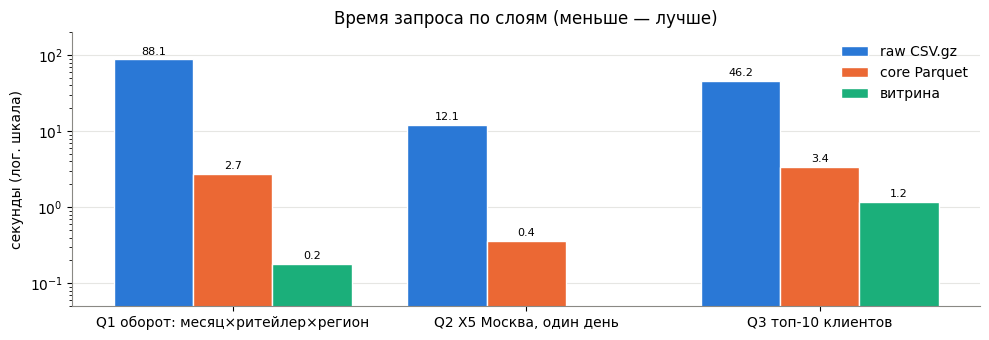

In [ ]:
if bench is not None:
    fig, ax = plt.subplots(figsize=(10, 3.5))
    layers = ["raw_csv_gz", "core_parquet", "mart"]
    names = {"raw_csv_gz": "raw CSV.gz", "core_parquet": "core Parquet", "mart": "витрина"}
    w = 0.27
    for j, layer in enumerate(layers):
        vals = [bench["queries_seconds"][q].get(layer) for q in qs.index]
        xs = [i + (j - 1) * w for i, v in enumerate(vals) if v is not None]
        bars = ax.bar(xs, [v for v in vals if v is not None], w, color=C[j], label=names[layer],
                      edgecolor="white", linewidth=1)
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    ax.set_yscale("log"); ax.set_ylim(0.05, 200)
    ax.set_xticks(range(len(qs)), ["Q1 оборот: месяц×ритейлер×регион", "Q2 X5 Москва, один день", "Q3 топ-10 клиентов"])
    ax.set_ylabel("секунды (лог. шкала)")
    ax.set_title("Время запроса по слоям"); ax.legend(frameon=False); plt.tight_layout()

In [ ]:
spark.stop()